# 모델링 v2 — `modeling.ipynb` 수정본

원본 `C:\t_project_1_1\modeling.ipynb`의 파생변수 + SMOTENC + 모델(Logistic / XGB / LGBM) 구성은 유지하고, 결과를 무효로 만드는 문제를 고쳤습니다.

| 원본 문제 | 수정 |
|---|---|
| `secondary_use_*_grade2/3`를 정답 `damage_grade`로 직접 만듦 → **정답 누수** | 삭제 |
| 지역별 사용률·유형 비율·평균 연식을 전체 데이터(검증·테스트·팀 홀드아웃 포함)로 계산 | 학습 fold에서만 계산하고, 검증 fold에는 그 값을 매핑. 처음 보는 지역은 학습 fold 전체 값으로 채움 |
| 지역×변수 카이제곱 변수 선택도 전체 데이터로 수행 | 학습 fold 안에서 수행 |
| 원본 CSV를 7:1.5:1.5로 직접 분할 (팀 홀드아웃과 다른 분할) | `load_development()` + 저장된 5-fold. 홀드아웃은 읽지 않음 |
| 보고 지표가 macro 평균뿐이고 test를 바로 평가 | labels=[1,2,3] Macro F1, 클래스별 P/R/F1, 혼동행렬. 홀드아웃 평가는 하지 않음 |
| Logistic `max_iter=100` 수렴 경고 | `max_iter`를 늘림 |
| CatBoost | 이 환경에 설치돼 있지 않아 제외 |

추가로, 한 요소씩 비교하기 위해 각 모델을 **SMOTENC 없이** 학습한 결과도 같은 fold에서 함께 보고합니다.
결과는 `outputs/t_project_v2/modeling/`(gitignore 대상)에 저장합니다.

In [ ]:
from pathlib import Path
import sys
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from imblearn.over_sampling import SMOTENC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

REPO = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "preprocess.py").exists()
)
sys.path.insert(0, str(REPO))

import preprocess as pp

SEED = 42
LABELS = [1, 2, 3]
GEO = pp.GEO

# 실행할 fold 수 (전체 실행은 5)
N_FOLDS_TO_RUN = 5

OUT = REPO / "outputs" / "t_project_v2" / "modeling"
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

X, y, ids, cv = pp.load_development(REPO / "data")
y = y.astype(int)
folds = list(cv.split())

assert X.shape == (208480, 38) and len(folds) == 5
print("development:", X.shape, "/ 결과 폴더:", OUT)

development: (208480, 38) / 결과 폴더: C:\Users\jhj31\project_1\earthquake\outputs\t_project_v2\modeling


## 1. 파생변수

**행 단위 파생변수**는 그 건물의 입력만 쓰므로 fold와 상관없이 계산해도 됩니다(원본 1~8번 중 누수 아닌 것).
**지역 집계 파생변수**(원본 9~10번)는 다른 건물 값을 모아 만드는 것이라 학습 fold에서만 규칙을 정합니다.

In [2]:
CONCRETE = [
    "has_superstructure_cement_mortar_stone",
    "has_superstructure_cement_mortar_brick",
    "has_superstructure_rc_non_engineered",
    "has_superstructure_rc_engineered"
]

MUD = [
    "has_superstructure_adobe_mud",
    "has_superstructure_mud_mortar_stone",
    "has_superstructure_mud_mortar_brick"
]

MATERIAL = [c for c in X.columns if c.startswith("has_superstructure_")]
SECONDARY = [c for c in X.columns if c.startswith("has_secondary_use_")]


def add_row_features(X):
    """건물 한 행의 입력만 쓰는 파생변수 (원본 3~8번). 정답은 쓰지 않음."""

    out = X.copy()

    # 원본 1~2번(secondary_use x 2/3등급)은 정답 누수라서 만들지 않음
    out["height_area_ratio"] = out["height_percentage"] / out["area_percentage"].clip(lower=1)
    out["material_count"] = out[MATERIAL].sum(axis=1)
    out["secondary_use_count"] = out[SECONDARY].sum(axis=1)
    out["height_per_floor"] = out["height_percentage"] / out["count_floors_pre_eq"].clip(lower=1)
    out["concrete_count"] = out[CONCRETE].sum(axis=1)
    out["mud_count"] = out[MUD].sum(axis=1)

    out["foundation_roof"] = out["foundation_type"] + "_" + out["roof_type"]
    out["ground_other_floor"] = out["ground_floor_type"] + "_" + out["other_floor_type"]
    out["foundation_ground"] = out["foundation_type"] + "_" + out["ground_floor_type"]
    out["surface_condition"] = out["land_surface_condition"] + "_" + out["ground_floor_type"]

    return out


def candidate_columns(frame):
    """지역 집계 대상: 문자형 변수와 has_ 0/1 변수 (지역 코드 제외)."""

    text = [
        c for c in frame.columns
        if c not in GEO and not pd.api.types.is_numeric_dtype(frame[c])
    ]

    return text + [c for c in frame.columns if c.startswith("has_")]


def fit_geo_features(train):
    """학습 fold에서 지역 집계 규칙을 정합니다 (원본 9~10번)."""

    rules = []

    for geo in GEO:
        for col in candidate_columns(train):
            table = pd.crosstab(train[geo], train[col])

            if min(table.shape) < 2:
                continue

            # 지역과 변수의 연관성 검정 (입력 변수끼리, 정답은 쓰지 않음)
            if chi2_contingency(table)[1] >= 0.05:
                continue

            if pd.api.types.is_numeric_dtype(train[col]):
                rules.append({
                    "name": f"{geo}_{col}_rate",
                    "kind": "rate",
                    "geo": geo,
                    "col": col,
                    "values": train.groupby(geo)[col].mean(),
                    "default": float(train[col].mean())
                })

            else:
                pair_size = train.groupby([geo, col]).size()
                geo_size = train.groupby(geo).size()

                rules.append({
                    "name": f"{geo}_{col}_freq",
                    "kind": "freq",
                    "geo": geo,
                    "col": col,
                    "values": pair_size / pair_size.index.get_level_values(0).map(geo_size).to_numpy(),
                    "default": train[col].value_counts(normalize=True)
                })

    for geo in GEO:
        rules.append({
            "name": f"{geo}_age_mean",
            "kind": "rate",
            "geo": geo,
            "col": "age",
            "values": train.groupby(geo)["age"].mean(),
            "default": float(train["age"].mean())
        })

    return rules


def apply_geo_features(frame, rules):
    """학습 fold 규칙을 적용합니다. 처음 보는 지역은 학습 fold 전체 값으로 채움."""

    new = {}

    for rule in rules:
        if rule["kind"] == "rate":
            new[rule["name"]] = (
                frame[rule["geo"]]
                .map(rule["values"])
                .fillna(rule["default"])
                .astype(float)
                .to_numpy()
            )

        else:
            keys = pd.MultiIndex.from_arrays([frame[rule["geo"]], frame[rule["col"]]])
            values = rule["values"].reindex(keys).to_numpy(dtype=float)
            fallback = frame[rule["col"]].map(rule["default"]).fillna(0).to_numpy(dtype=float)
            new[rule["name"]] = np.where(np.isnan(values), fallback, values)

    return pd.concat([frame, pd.DataFrame(new, index=frame.index)], axis=1)


row_features = add_row_features(X)
print("행 단위 파생변수 추가 후:", row_features.shape)

행 단위 파생변수 추가 후: (208480, 48)


## 2. fold별 학습: 전처리 → (SMOTENC) → 원-핫 → 모델

원본과 같은 순서입니다. 수치형은 표준화, 범주형(문자·0/1·지역 코드)은 순서 인코딩 후 SMOTENC로 학습 fold만 오버샘플링하고, 그 뒤 원-핫으로 바꿔 모델에 넣습니다.
SMOTENC 결과는 fold마다 한 번만 만들어 세 모델이 같이 씁니다.

In [3]:
def make_models():
    return {
        "Logistic": LogisticRegression(random_state=SEED, max_iter=2000),
        "XGB": XGBClassifier(random_state=SEED, n_jobs=4, tree_method="hist", verbosity=0),
        "LGBM": LGBMClassifier(random_state=SEED, n_jobs=4, verbosity=-1)
    }


def metrics(y_true, y_pred):
    report = classification_report(
        y_true, y_pred, labels=LABELS, output_dict=True, zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)

    result = {
        "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred)
    }

    for grade in LABELS:
        for name in ["precision", "recall", "f1-score"]:
            result[f"{name}_{grade}"] = report[str(grade)][name]

    result["error_3_to_2"] = cm[2, 1] / max(cm[2].sum(), 1)

    return result


rows = []
oof = {}
feature_counts = []

for fold_number, (tr, va) in enumerate(folds[:N_FOLDS_TO_RUN]):
    started = time.perf_counter()

    train = row_features.iloc[tr]
    valid = row_features.iloc[va]

    # 지역 집계 규칙은 학습 fold에서만
    rules = fit_geo_features(train)
    train = apply_geo_features(train, rules)
    valid = apply_geo_features(valid, rules)

    cat_cols = GEO + candidate_columns(train)
    num_cols = [c for c in train.columns if c not in cat_cols]

    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)
    ])

    train_x = preprocessor.fit_transform(train)
    valid_x = preprocessor.transform(valid)

    cat_idx = list(range(len(num_cols), len(num_cols) + len(cat_cols)))

    # 0,1,2 라벨 (XGB 요구사항)
    train_y = y.iloc[tr].to_numpy() - 1

    smote_started = time.perf_counter()
    smote_x, smote_y = SMOTENC(
        categorical_features=cat_idx, random_state=SEED
    ).fit_resample(train_x, train_y)
    smote_seconds = time.perf_counter() - smote_started

    feature_counts.append({
        "fold": fold_number,
        "geo_rules": len(rules),
        "num_cols": len(num_cols),
        "cat_cols": len(cat_cols),
        "train_n": len(train_y),
        "smote_n": len(smote_y),
        "smote_seconds": smote_seconds
    })

    for sampling, (fit_x, fit_y) in {
        "SMOTENC": (smote_x, smote_y),
        "none": (train_x, train_y)
    }.items():
        onehot = ColumnTransformer(
            [("cat", OneHotEncoder(handle_unknown="ignore"), cat_idx)],
            remainder="passthrough",
            sparse_threshold=1.0
        )

        fit_matrix = onehot.fit_transform(fit_x)
        valid_matrix = onehot.transform(valid_x)

        for model_name, model in make_models().items():
            model_started = time.perf_counter()
            model.fit(fit_matrix, fit_y)
            pred = model.predict(valid_matrix).astype(int) + 1

            name = f"{model_name} / {sampling}"
            oof.setdefault(name, np.zeros(len(X), dtype=int))[va] = pred

            rows.append({
                "name": name,
                "model": model_name,
                "sampling": sampling,
                "fold": fold_number,
                "train_n": len(fit_y),
                **metrics(y.iloc[va], pred),
                "seconds": time.perf_counter() - model_started
            })

            print(
                f"fold {fold_number} {name:<20} Macro F1 {rows[-1]['macro_f1']:.5f}",
                flush=True
            )

    pd.DataFrame(rows).to_csv(OUT / "cv_folds.csv", index=False, encoding="utf-8-sig")
    print(f"fold {fold_number} 완료: {time.perf_counter() - started:.0f}초 (SMOTENC {smote_seconds:.0f}초)", flush=True)

feature_table = pd.DataFrame(feature_counts)
feature_table.to_csv(OUT / "fold_feature_counts.csv", index=False, encoding="utf-8-sig")
display(feature_table)

fold 0 Logistic / SMOTENC   Macro F1 0.67470


fold 0 XGB / SMOTENC        Macro F1 0.68361


fold 0 LGBM / SMOTENC       Macro F1 0.68391


fold 0 Logistic / none      Macro F1 0.68528


fold 0 XGB / none           Macro F1 0.67843


...

fold 4 Logistic / none      Macro F1 0.68455


fold 4 XGB / none           Macro F1 0.67085


fold 4 LGBM / none          Macro F1 0.67192


fold 4 완료: 907초 (SMOTENC 521초)


,fold,geo_rules,num_cols,cat_cols,train_n,smote_n,smote_seconds
0,0,93,104,37,166784,284655,1338.961342
1,1,94,105,37,166784,284655,1257.925961
2,2,93,104,37,166784,284658,1030.630449
3,3,93,104,37,166784,284658,683.981964
4,4,92,103,37,166784,284658,520.544869


## 3. 결과

`diff_vs_none`은 같은 모델의 SMOTENC 없는 버전과 fold별로 짝지은 Macro F1 차이입니다.
참고: `tests/test_5_v2.ipynb`의 LGBM_raw(원본 38열, LightGBM 범주형 직접 처리)도 같은 5-fold 기준이라 바로 비교할 수 있습니다.

,name,model,sampling,macro_f1,macro_f1_std,accuracy,recall_1,recall_2,recall_3,error_3_to_2,seconds,diff_vs_none
3,Logistic / none,Logistic,none,0.68533,0.00081,0.74024,0.51281,0.83786,0.63982,0.35285,1072.24994,0.00000
0,LGBM / SMOTENC,LGBM,SMOTENC,0.68099,0.00316,0.72571,0.57451,0.80057,0.64202,0.35026,571.23563,0.00539
4,XGB / SMOTENC,XGB,SMOTENC,0.67945,0.00298,0.72441,0.56480,0.79407,0.65198,0.34037,265.10459,0.00577
1,LGBM / none,LGBM,none,0.67560,0.00415,0.73556,0.47749,0.85610,0.60501,0.39069,144.08792,0.00000
5,XGB / none,XGB,none,0.67369,0.00380,0.73480,0.46982,0.85581,0.60544,0.39032,67.04555,0.00000
2,Logistic / SMOTENC,Logistic,SMOTENC,0.67324,0.00167,0.70237,0.76581,0.67592,0.72905,0.24307,2008.32324,-0.01209


5-fold 평균 최고: Logistic / none
              precision    recall  f1-score   support

           1     0.6574    0.5128    0.5762     20099
           2     0.7450    0.8379    0.7887    118607
           3     0.7513    0.6398    0.6911     69774

    accuracy                         0.7402    208480
   macro avg     0.7179    0.6635    0.6853    208480
weighted avg     0.7387    0.7402    0.7356    208480



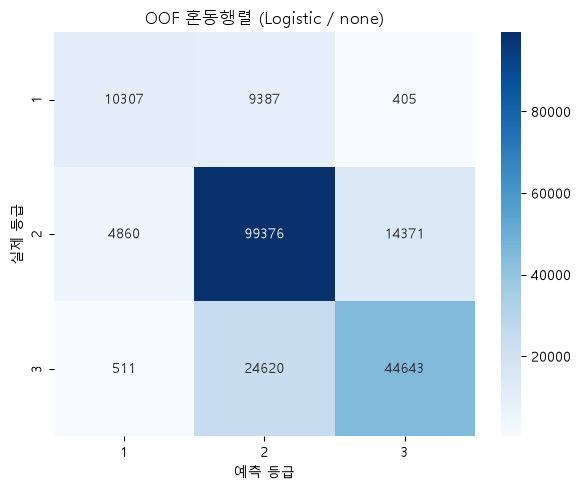

In [4]:
cv_table = pd.DataFrame(rows)
wide = cv_table.pivot(index="fold", columns="name", values="macro_f1")

summary = (
    cv_table.groupby(["name", "model", "sampling"])
    .agg(
        macro_f1=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        accuracy=("accuracy", "mean"),
        recall_1=("recall_1", "mean"),
        recall_2=("recall_2", "mean"),
        recall_3=("recall_3", "mean"),
        error_3_to_2=("error_3_to_2", "mean"),
        seconds=("seconds", "sum")
    )
    .reset_index()
)

summary["diff_vs_none"] = [
    (wide[name] - wide[f"{model} / none"]).mean()
    for name, model in zip(summary["name"], summary["model"])
]

summary = summary.sort_values("macro_f1", ascending=False)
summary.to_csv(OUT / "cv_summary.csv", index=False, encoding="utf-8-sig")
display(summary.round(5))

best = summary.iloc[0]["name"]
print(f"{N_FOLDS_TO_RUN}-fold 평균 최고:", best)

# 실행한 fold의 검증 행만 사용 (OOF 예측이 채워진 행)
covered = np.sort(np.concatenate([va for _, va in folds[:N_FOLDS_TO_RUN]]))
y_covered = y.iloc[covered]
pred_covered = oof[best][covered]

print(classification_report(y_covered, pred_covered, labels=LABELS, digits=4, zero_division=0))

cm = confusion_matrix(y_covered, pred_covered, labels=LABELS)
pd.DataFrame(cm, index=LABELS, columns=["pred1", "pred2", "pred3"]).reset_index(names="actual").to_csv(
    OUT / "oof_confusion_matrix_best.csv", index=False, encoding="utf-8-sig"
)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=ax)
ax.set_title(f"OOF 혼동행렬 ({best})")
ax.set_xlabel("예측 등급")
ax.set_ylabel("실제 등급")
plt.tight_layout()
plt.savefig(OUT / "oof_confusion_matrix_best.png", dpi=150)
plt.show()

In [5]:
# 무결성 검사
assert cv_table.groupby("name")["fold"].nunique().eq(N_FOLDS_TO_RUN).all()
assert not any("grade2" in c or "grade3" in c for c in apply_geo_features(row_features.iloc[:5], fit_geo_features(row_features.iloc[folds[0][0]])).columns)
assert not list(OUT.glob("*holdout*"))

for name, pred in oof.items():
    assert set(np.unique(pred[covered])) <= set(LABELS)

print("fold 수·정답 파생변수 없음·홀드아웃 미사용 검사를 통과했습니다.")

fold 수·정답 파생변수 없음·홀드아웃 미사용 검사를 통과했습니다.
